# Applied AI - Assignment 2 (CIFAR-10)

Amir Hamza<br>

This CNN has been tested both on cloud computing and local hardware. (Through Google Collab using a T4 GPU and on a Personal Laptop containing a Laptop 3050 through the latest Tensorflow-GPU Docker Image)

### Google Colab 
<pre>Sign in using a Google account.<br>
Open Notebook <br>
    * File->Open Notebook->Upload <br>
    * Drag and drop file <br>
Change GPU <br>
    * Press the dropdown arrow beside "Connect" (Top Right corner) <br>
    * Press "Change Runtime type"<br>
    * Select "T4-GPU" and Save<br>
    * Press the "Connect" Button<br>
Press the Run all button to run code
</pre>

In [1]:


# === Import Libraries ===
import tensorflow as tf
from keras import datasets, layers, models
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

import tensorflow.python.client.device_lib as gpucheck
import re
from functools import partial

2025-09-11 15:14:53.726671: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-09-11 15:14:53.742414: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1757603693.763294   62582 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1757603693.769808   62582 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1757603693.783353   62582 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

In [2]:
tf.random.set_seed(73)
np.random.seed(73)

print("TensorFlow version:", tf.__version__)

# Finds and prints GPU name using Regex
for x in gpucheck.list_local_devices(): 
    reg = re.compile(r"name: (\w+ )+(\w)+,")
    result = reg.search(x.physical_device_desc)
    if result:
        string = result.group(0)
        print(f"GPU {string}")
        
# === Load CIFAR-10 Dataset ===
(x_train, y_train), (x_test, y_test) = datasets.cifar10.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0
y_train, y_test = y_train.flatten(), y_test.flatten()

class_names = ["airplane","automobile","bird","cat","deer",
            "dog","frog","horse","ship","truck"]

print("Training data shape:", x_train.shape)
print("Test data shape:", x_test.shape)

TensorFlow version: 2.19.0
GPU name: NVIDIA GeForce RTX 3050 Laptop GPU,


I0000 00:00:1757603697.940025   62582 gpu_device.cc:2019] Created device /device:GPU:0 with 1768 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Training data shape: (50000, 32, 32, 3)
Test data shape: (10000, 32, 32, 3)


In [3]:

# === Load CIFAR-10 Dataset ===
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0
y_train = y_train.flatten()
y_test  = y_test.flatten()
 
class_names = ["airplane","automobile","bird","cat","deer",
               "dog","frog","horse","ship","truck"]
 
print("Training data shape:", x_train.shape)
print("Test data shape:", x_test.shape)


# Code for Data Augmentation
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name="data_augmentation")
 
# === Convolutional Neural Network ===

kernel = (4, 4)

model = models.Sequential([

    layers.Input((32, 32, 3)),
    data_augmentation,

    layers.Conv2D(64, kernel, activation='relu', padding="same"),
    layers.Conv2D(64, kernel, activation='relu', padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2),
    layers.Dropout(0.5),

    layers.Conv2D(128, kernel, activation='relu', padding="same"),
    layers.Conv2D(128, kernel, activation='relu', padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2),
    layers.Dropout(0.5),

    layers.Conv2D(256, kernel, activation='relu', padding="same"),
    layers.Conv2D(256, kernel, activation='relu', padding="same"),
    layers.BatchNormalization(),

    layers.Flatten(),
    layers.Dense(units=128, activation='relu'),
    layers.Dense(units=10, activation="softmax"),
])


model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
            loss='sparse_categorical_crossentropy',
            metrics=['accuracy'])
 
# === Callbacks ===

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=7, restore_best_weights=True
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3
)
 

 
 
 

Training data shape: (50000, 32, 32, 3)
Test data shape: (10000, 32, 32, 3)


I0000 00:00:1757603702.705079   62582 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1768 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


In [4]:
# === Train ===
history = model.fit(x_train, y_train,
                    epochs=50,
                    validation_data=(x_test, y_test),
                    batch_size=256,
                    callbacks=[early_stop, reduce_lr]
                    )
 
 

Epoch 1/50


E0000 00:00:1757603708.503340   62582 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1757603710.737939   62742 cuda_dnn.cc:529] Loaded cuDNN version 90300
2025-09-11 15:15:13.237240: W external/local_xla/xla/tsl/framework/bfc_allocator.cc:310] Allocator (GPU_0_bfc) ran out of memory trying to allocate 872.25MiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.


196/196 ━━━━━━━━━━━━━━━━━━━━ 44s 170ms/step - accuracy: 0.2850 - loss: 2.2082 - val_accuracy: 0.1105 - val_loss: 4.6985 - learning_rate: 0.0010
Epoch 2/50
196/196 ━━━━━━━━━━━━━━━━━━━━ 31s 160ms/step - accuracy: 0.4940 - loss: 1.4170 - val_accuracy: 0.3684 - val_loss: 1.8950 - learning_rate: 0.0010
Epoch 3/50
196/196 ━━━━━━━━━━━━━━━━━━━━ 31s 161ms/step - accuracy: 0.5629 - loss: 1.2150 - val_accuracy: 0.5661 - val_loss: 1.2370 - learning_rate: 0.0010
Epoch 4/50
196/196 ━━━━━━━━━━━━━━━━━━━━ 32s 161ms/step - accuracy: 0.6116 - loss: 1.0929 - val_accuracy: 0.6531 - val_loss: 1.0323 - learning_rate: 0.0010
Epoch 5/50
196/196 ━━━━━━━━━━━━━━━━━━━━ 31s 160ms/step - accuracy: 0.6545 - loss: 0.9784 - val_accuracy: 0.6898 - val_loss: 0.9066 - learning_rate: 0.0010
Epoch 6/50
196/196 ━━━━━━━━━━━━━━━━━━━━ 32s 161ms/step - accuracy: 0.6829 - loss: 0.9041 - val_accuracy: 0.6962 - val_loss: 0.8900 - learning_rate: 0.0010
Epoch 7/50
196/196 ━━━━━━━━━━━━━━━━━━━━ 31s 160ms/step - accuracy: 0.7015 - loss:

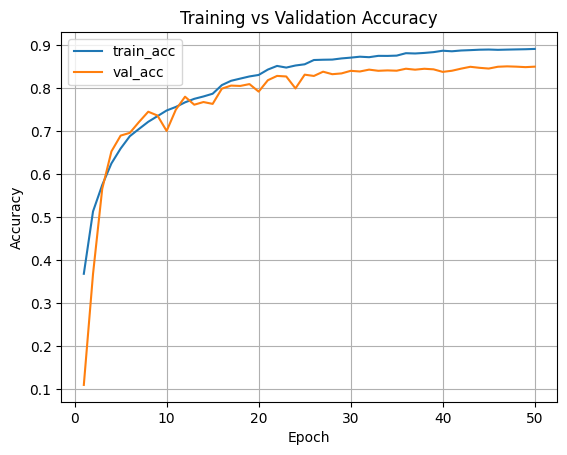

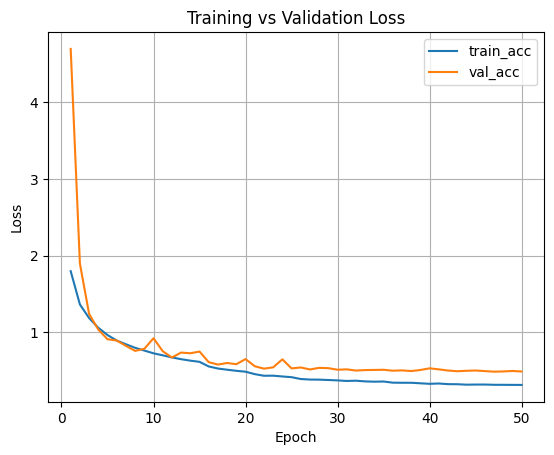

In [5]:

# === Plot Training History ===
## Write your code to plot the training history

hist_dict = history.history
epochs = range(1, len(hist_dict["loss"]) + 1)

# Accuracy Graph
plt.figure()
plt.plot(epochs, hist_dict["accuracy"], label="train_acc")
plt.plot(epochs, hist_dict["val_accuracy"], label="val_acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

#Loss Graph
plt.plot(epochs, hist_dict["loss"], label="train_acc")
plt.plot(epochs, hist_dict["val_loss"], label="val_acc")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


=== Classification Report (per-class Precision / Recall / F1) ===
              precision    recall  f1-score   support

    airplane     0.8772    0.8790    0.8781      1000
  automobile     0.9049    0.9420    0.9231      1000
        bird     0.8378    0.7750    0.8052      1000
         cat     0.7713    0.6440    0.7019      1000
        deer     0.8579    0.8090    0.8327      1000
         dog     0.8069    0.7690    0.7875      1000
        frog     0.7749    0.9500    0.8535      1000
       horse     0.8851    0.9010    0.8930      1000
        ship     0.9164    0.9210    0.9187      1000
       truck     0.8717    0.9170    0.8938      1000

    accuracy                         0.8507     10000
   macro avg     0.8504    0.8507    0.8488     10000
weighted avg     0.8504    0.8507    0.8488     10000



<Figure size 800x800 with 0 Axes>

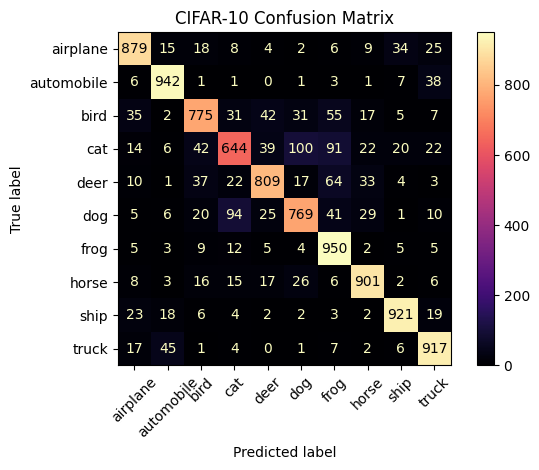

In [6]:
# === Confusion Matrix and R1 Scores===
# Write your code here to generate the confusion Matrix
y_proba = model.predict(x_test, batch_size=64, verbose=0)
y_pred = np.argmax(y_proba, axis=1)

print("\n=== Classification Report (per-class Precision / Recall / F1) ===")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

# Confusion Matrix Graph
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

plt.figure(figsize=(8, 8))
disp.plot(include_values=True, cmap="magma", xticks_rotation=45, colorbar=True)
plt.title("CIFAR-10 Confusion Matrix")
plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


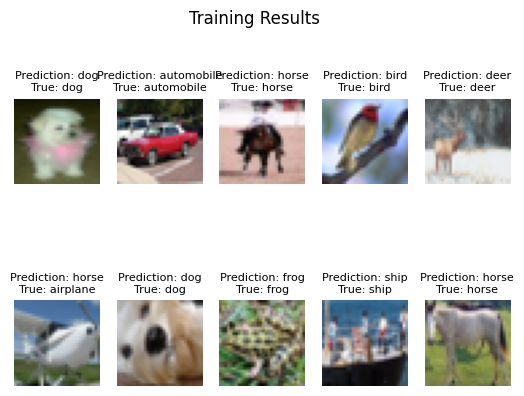

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step


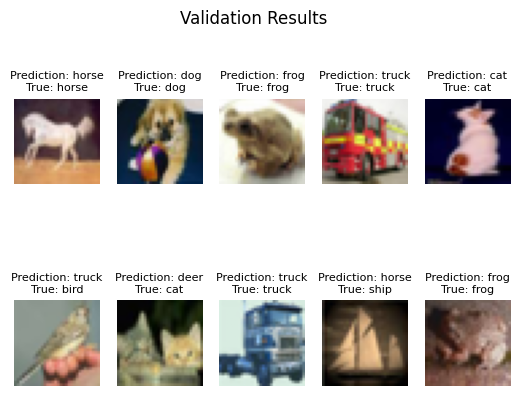

In [47]:
#Validation Images
x, y = x_test, y_test

train_range = 3000
val_range = 5080

for count in range(train_range,train_range+10, 1):
    image = x[count, :, :, :]
    prediction_scores = model.predict(np.expand_dims(image, axis=0))
    predicted_index = np.argmax(prediction_scores)
    
    true_label = f"True: {class_names[y[count]]}"
    predicted_label = f"Prediction: {class_names[predicted_index]}"    

    plt.suptitle("Training Results")
    plt.subplot(2,5,count-train_range+1)
    plt.imshow(image)
    plt.axis('off')

    plt.title(f"{predicted_label}\n{true_label}").set_fontsize(8)
plt.show()

for count in range(val_range,val_range+10, 1):
    image = x[count, :, :, :]
    prediction_scores = model.predict(np.expand_dims(image, axis=0))
    predicted_index = np.argmax(prediction_scores)
    
    true_label = f"True: {class_names[y[count]]}"
    predicted_label = f"Prediction: {class_names[predicted_index]}"    

    plt.suptitle("Validation Results")
    plt.subplot(2,5,count-val_range+1)
    plt.imshow(image)
    plt.axis('off')

    plt.title(f"{predicted_label}\n{true_label}").set_fontsize(8)
plt.show()